In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Set random seed for reproducibility
torch.manual_seed(42)

# Set device dynamically (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# -------------------------------------------------------------------------
# 1. DYNAMIC Z-SCORE STATISTIC COMPUTATION
# -------------------------------------------------------------------------
# Load raw training dataset to calculate exact dataset-wide mean and std
raw_dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Stack all images into a single tensor [60000, 1, 28, 28]
all_images = torch.stack([img for img, _ in raw_dataset], dim=0)

# Calculate global mean and standard deviation across all pixels
calculated_mean = all_images.mean().item()
calculated_std = all_images.std().item()

print(f"Calculated Mean: {calculated_mean:.4f}")
print(f"Calculated Std : {calculated_std:.4f}")

# -------------------------------------------------------------------------
# 2. DATA PREPROCESSING & TRANSFORMS (Standardization N(0, 1))
# -------------------------------------------------------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((calculated_mean,), (calculated_std,))
])

# Load datasets with real Z-Score normalization applied
full_train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# -------------------------------------------------------------------------
# 3. TRAIN / VALIDATION (DEV) SPLIT (%80 Train, %20 Validation from Train Set)
# -------------------------------------------------------------------------
train_size = int(0.8 * len(full_train_dataset))  # 48,000 samples
val_size = len(full_train_dataset) - train_size   # 12,000 samples

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# -------------------------------------------------------------------------
# 4. DATALOADERS (Mini-Batch SGD Strategy, batch_size=64)
# -------------------------------------------------------------------------
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1000, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

print(f"\nDataset Splits:")
print(f"Train Set      : {len(train_dataset)} samples ({len(train_loader)} batches)")
print(f"Validation Set : {len(val_dataset)} samples ({len(val_loader)} batches)")
print(f"Test Set       : {len(test_dataset)} samples ({len(test_loader)} batches)")

Using device: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 11.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.22MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.3MB/s]


Calculated Mean: 0.2860
Calculated Std : 0.3530

Dataset Splits:
Train Set      : 48000 samples (750 batches)
Validation Set : 12000 samples (12 batches)
Test Set       : 10000 samples (10 batches)


In [ ]:
# -------------------------------------------------------------------------
# 5. MODEL ARCHITECTURE (Deep Neural Network - Pyramid Structure)
# -------------------------------------------------------------------------
class DeepNeuralNetwork(nn.Module):
    def __init__(self):
        super(DeepNeuralNetwork, self).__init__()

        # Flatten 2D image tensor [1, 28, 28] into a 1D feature vector [784]
        self.flatten = nn.Flatten()

        # Pyramid Architecture: Progressive dimensionality reduction
        self.network = nn.Sequential(
            # Layer 1: Input Layer (784 -> 512)
            nn.Linear(28 * 28, 512),
            nn.ReLU(),

            # Layer 2: Hidden Layer 1 (512 -> 256)
            nn.Linear(512, 256),
            nn.ReLU(),

            # Layer 3: Hidden Layer 2 (256 -> 128)
            nn.Linear(256, 128),
            nn.ReLU(),

            # Layer 4: Hidden Layer 3 (128 -> 64)
            nn.Linear(128, 64),
            nn.ReLU(),

            # Layer 5: Output Layer (64 -> 10 Classes)
            nn.Linear(64, 10)
        )

    def forward(self, x):
        # Apply spatial flattening to batch input
        x = self.flatten(x)
        # Pass flattened vector through the fully-connected network
        logits = self.network(x)
        return logits

# -------------------------------------------------------------------------
# 6. MODEL INSTANTIATION & DEVICE ASSIGNMENT
# -------------------------------------------------------------------------
# Instantiate model and transfer parameters to active compute device (GPU/CPU)
model = DeepNeuralNetwork().to(device)

print(model)

DeepNeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
# -------------------------------------------------------------------------
# 7. LOSS FUNCTION & OPTIMIZER CONFIGURATION
# -------------------------------------------------------------------------
# Define classification loss function (combines Softmax and Cross Entropy)
criterion = nn.CrossEntropyLoss()

# Configure Adam optimizer with L2 regularization (Weight Decay)
optimizer = optim.Adam(
    model.parameters(),    # Model parameters to update during backpropagation
    lr=0.001,              # Learning rate (alpha)
    betas=(0.9, 0.999),    # Exponential decay rates for momentum and RMSprop
    weight_decay=1e-4      # L2 Regularization lambda factor
)

# -------------------------------------------------------------------------
# VERIFICATION
# -------------------------------------------------------------------------
print("Loss function and optimizer successfully initialized.")
print(f"Criterion: {criterion}")
print(f"Optimizer: {optimizer}")

Loss function and optimizer successfully initialized.
Criterion: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [ ]:
# -------------------------------------------------------------------------
# 8. TRAINING & VALIDATION LOOPS DEFINITION
# -------------------------------------------------------------------------
def train_epoch(model, dataloader, criterion, optimizer, device):
    """Executes one full training pass over the dataset (Forward + Backward)."""
    model.train()  # Enable training mode (activates Dropout & BatchNorm dynamic updates)
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass & Loss calculation
        optimizer.zero_grad()  # Reset accumulated gradients from previous batch
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass & Weight updates
        loss.backward()        # Compute dW and db using autograd (Backpropagation)
        optimizer.step()       # Update weights via Adam optimization rules

        # Tracking performance metrics
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate_epoch(model, dataloader, criterion, device):
    """Executes one evaluation pass over the validation dataset (No Gradients)."""
    model.eval()   # Enable evaluation mode (disables Dropout & freezes BatchNorm stats)
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # Disable gradient tracking for speed and memory efficiency
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


# -------------------------------------------------------------------------
# 9. PIPELINE EXECUTION & METRICS COLLECTION
# -------------------------------------------------------------------------
epochs = 15
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

print("Starting training pipeline...")
for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)

    # Store metrics for visualization and evaluation
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

Starting training pipeline...
Epoch [01/15] | Train Loss: 0.5136 - Train Acc: 81.06% | Val Loss: 0.4164 - Val Acc: 84.20%
Epoch [02/15] | Train Loss: 0.3724 - Train Acc: 86.41% | Val Loss: 0.3652 - Val Acc: 86.62%
Epoch [03/15] | Train Loss: 0.3400 - Train Acc: 87.45% | Val Loss: 0.3557 - Val Acc: 87.20%
Epoch [04/15] | Train Loss: 0.3129 - Train Acc: 88.36% | Val Loss: 0.3437 - Val Acc: 87.58%
Epoch [05/15] | Train Loss: 0.2942 - Train Acc: 88.95% | Val Loss: 0.3541 - Val Acc: 87.45%
Epoch [06/15] | Train Loss: 0.2802 - Train Acc: 89.60% | Val Loss: 0.3649 - Val Acc: 86.91%
Epoch [07/15] | Train Loss: 0.2665 - Train Acc: 90.12% | Val Loss: 0.3295 - Val Acc: 88.38%
Epoch [08/15] | Train Loss: 0.2544 - Train Acc: 90.53% | Val Loss: 0.3156 - Val Acc: 88.59%
Epoch [09/15] | Train Loss: 0.2450 - Train Acc: 90.80% | Val Loss: 0.3293 - Val Acc: 88.20%
Epoch [10/15] | Train Loss: 0.2371 - Train Acc: 91.04% | Val Loss: 0.3232 - Val Acc: 88.82%
Epoch [11/15] | Train Loss: 0.2259 - Train Acc: 91

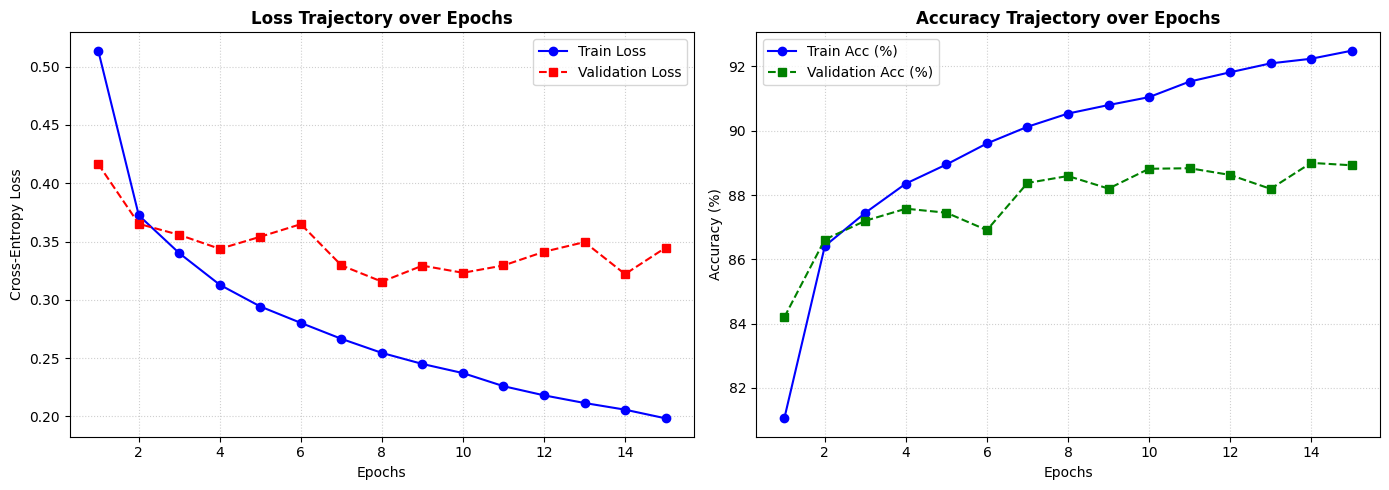

In [ ]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 10. METRICS VISUALIZATION & OVERFITTING ANALYSIS
# -------------------------------------------------------------------------
epochs_range = range(1, epochs + 1)

# Grafik penceresi oluşturma (2 yan yana grafik)
plt.figure(figsize=(14, 5))

# Subplot 1: Loss Değişimi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', color='blue', linestyle='-', marker='o')
plt.plot(epochs_range, val_losses, label='Validation Loss', color='red', linestyle='--', marker='s')
plt.title('Loss Trajectory over Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Cross-Entropy Loss', fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Accuracy Değişimi
plt.subplot(1, 2, 2)
plt.plot(epochs_range, [acc * 100 for acc in train_accuracies], label='Train Acc (%)', color='blue', linestyle='-', marker='o')
plt.plot(epochs_range, [acc * 100 for acc in val_accuracies], label='Validation Acc (%)', color='green', linestyle='--', marker='s')
plt.title('Accuracy Trajectory over Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Accuracy (%)', fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

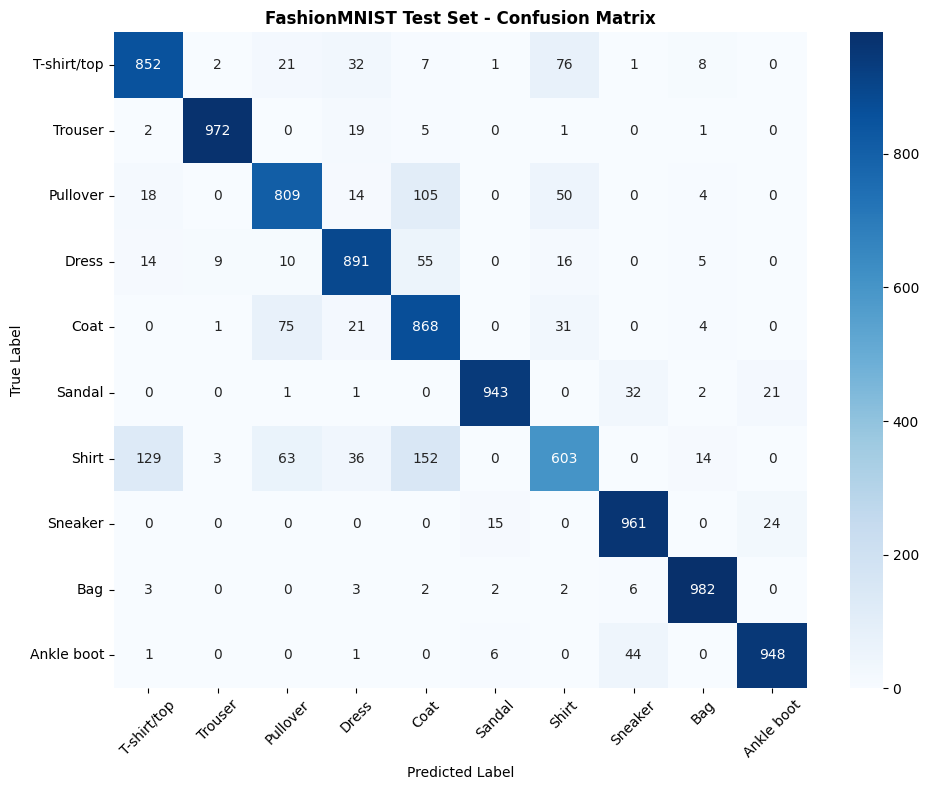


Detailed Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.84      1000
     Trouser       0.98      0.97      0.98      1000
    Pullover       0.83      0.81      0.82      1000
       Dress       0.88      0.89      0.88      1000
        Coat       0.73      0.87      0.79      1000
      Sandal       0.98      0.94      0.96      1000
       Shirt       0.77      0.60      0.68      1000
     Sneaker       0.92      0.96      0.94      1000
         Bag       0.96      0.98      0.97      1000
  Ankle boot       0.95      0.95      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



In [ ]:
# -------------------------------------------------------------------------
# 11. FINAL TEST EVALUATION & CONFUSION MATRIX
# -------------------------------------------------------------------------
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

# FashionMNIST class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Confusion matrix calculation
cm = confusion_matrix(all_targets, all_preds)

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('FashionMNIST Test Set - Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=10)
plt.ylabel('True Label', fontsize=10)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Sınıf bazlı detaylı rapor (Precision, Recall, F1-Score)
print("\nDetailed Classification Report:")
print(classification_report(all_targets, all_preds, target_names=class_names))

In [ ]:
# -------------------------------------------------------------------------
# 5. ENHANCED MODEL ARCHITECTURE (DNN + BatchNorm + Dropout Regularization)
# -------------------------------------------------------------------------
class EnhancedFashionMLP(nn.Module):
    def __init__(self):
        super(EnhancedFashionMLP, self).__init__()

        # Flatten 2D image tensor [1, 28, 28] into a 1D feature vector [784]
        self.flatten = nn.Flatten()

        # Pyramid Architecture with Batch Normalization & Dropout Regularization
        self.network = nn.Sequential(
            # Layer 1: Input Layer (784 -> 512)
            nn.Linear(28 * 28, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            # Layer 2: Hidden Layer 1 (512 -> 256)
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            # Layer 3: Hidden Layer 2 (256 -> 128)
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            # Layer 4: Hidden Layer 3 (128 -> 64)
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            # Layer 5: Output Layer (64 -> 10 Classes)
            nn.Linear(64, 10)
        )

    def forward(self, x):
        # Apply spatial flattening to batch input
        x = self.flatten(x)
        # Pass flattened vector through the fully-connected network
        logits = self.network(x)
        return logits

In [ ]:
# -------------------------------------------------------------------------
# HYPERPARAMETER TUNING: COARSE SEARCH (3 EPOCHS PER TRIAL)
# -------------------------------------------------------------------------
# Define logarithmic search space for Learning Rate (alpha) and Weight Decay (lambda)
search_space = [
    {'lr': 1e-2, 'weight_decay': 1e-3},
    {'lr': 1e-3, 'weight_decay': 1e-4},
    {'lr': 1e-3, 'weight_decay': 1e-3},
    {'lr': 5e-4, 'weight_decay': 1e-4}
]

best_coarse_loss = float('inf')
best_coarse_params = None

print("--- Starting Coarse Hyperparameter Search ---")

for idx, params in enumerate(search_space):
    # Re-initialize fresh model and optimizer for each trial
    temp_model = EnhancedFashionMLP().to(device)
    temp_optimizer = optim.Adam(
        temp_model.parameters(),
        lr=params['lr'],
        weight_decay=params['weight_decay']
    )

    print(f"\n[Trial {idx+1}/{len(search_space)}] Testing LR: {params['lr']} | Weight Decay: {params['weight_decay']}")

    # Run short 3-epoch evaluation
    for epoch in range(3):
        train_loss, train_acc = train_epoch(temp_model, train_loader, criterion, temp_optimizer, device)
        val_loss, val_acc = validate_epoch(temp_model, val_loader, criterion, device)
        print(f"  Epoch {epoch+1}/3 -> Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

    # Track parameter set with best validation loss
    if val_loss < best_coarse_loss:
        best_coarse_loss = val_loss
        best_coarse_params = params

print("\n" + "="*50)
print(f"Coarse Search Completed!")
print(f"Best Parameters Found : LR = {best_coarse_params['lr']} | Weight Decay = {best_coarse_params['weight_decay']}")
print(f"Best Validation Loss  : {best_coarse_loss:.4f}")
print("="*50)

--- Starting Coarse Hyperparameter Search ---

[Trial 1/4] Testing LR: 0.01 | Weight Decay: 0.001
  Epoch 1/3 -> Train Loss: 0.7944 | Val Loss: 0.8596 | Val Acc: 69.46%
  Epoch 2/3 -> Train Loss: 0.7784 | Val Loss: 0.6384 | Val Acc: 77.00%
  Epoch 3/3 -> Train Loss: 0.7671 | Val Loss: 0.5843 | Val Acc: 79.27%

[Trial 2/4] Testing LR: 0.001 | Weight Decay: 0.0001
  Epoch 1/3 -> Train Loss: 0.6684 | Val Loss: 0.4241 | Val Acc: 84.86%
  Epoch 2/3 -> Train Loss: 0.4745 | Val Loss: 0.3648 | Val Acc: 86.81%
  Epoch 3/3 -> Train Loss: 0.4335 | Val Loss: 0.3473 | Val Acc: 87.24%

[Trial 3/4] Testing LR: 0.001 | Weight Decay: 0.001
  Epoch 1/3 -> Train Loss: 0.6778 | Val Loss: 0.4221 | Val Acc: 85.02%
  Epoch 2/3 -> Train Loss: 0.5062 | Val Loss: 0.4171 | Val Acc: 85.20%
  Epoch 3/3 -> Train Loss: 0.4813 | Val Loss: 0.4007 | Val Acc: 85.47%

[Trial 4/4] Testing LR: 0.0005 | Weight Decay: 0.0001
  Epoch 1/3 -> Train Loss: 0.7362 | Val Loss: 0.4165 | Val Acc: 85.60%
  Epoch 2/3 -> Train Loss: 0.4

In [ ]:
# -------------------------------------------------------------------------
# HYPERPARAMETER TUNING: FINE SEARCH (ENHANCED GRID & 5 EPOCHS)
# -------------------------------------------------------------------------
# Tight, high-resolution search grid around Coarse Search winner (LR=0.001, WD=1e-4)
fine_search_space = [
    {'lr': 0.0007, 'weight_decay': 1e-4},
    {'lr': 0.0009, 'weight_decay': 1e-4},
    {'lr': 0.0010, 'weight_decay': 5e-5},
    {'lr': 0.0010, 'weight_decay': 1e-4},
    {'lr': 0.0012, 'weight_decay': 2e-4}
]

best_fine_loss = float('inf')
best_fine_params = None

print("--- Starting Enhanced Fine Hyperparameter Search (5 Epochs per Trial) ---")

for idx, params in enumerate(fine_search_space):
    # Re-initialize fresh model and optimizer for each fine trial
    temp_model = EnhancedFashionMLP().to(device)
    temp_optimizer = optim.Adam(
        temp_model.parameters(),
        lr=params['lr'],
        weight_decay=params['weight_decay']
    )

    print(f"\n[Fine Trial {idx+1}/{len(fine_search_space)}] Testing LR: {params['lr']} | Weight Decay: {params['weight_decay']}")

    # 5 epochs to reduce variance and smooth out initial random weight noise
    for epoch in range(5):
        train_loss, train_acc = train_epoch(temp_model, train_loader, criterion, temp_optimizer, device)
        val_loss, val_acc = validate_epoch(temp_model, val_loader, criterion, device)
        print(f"  Epoch {epoch+1}/5 -> Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

    # Track the configuration with lowest validation loss
    if val_loss < best_fine_loss:
        best_fine_loss = val_loss
        best_fine_params = params

print("\n" + "="*55)
print("Fine Search Completed Successfully!")
print(f"Optimal Parameters Found : LR = {best_fine_params['lr']} | Weight Decay = {best_fine_params['weight_decay']}")
print(f"Best Fine Validation Loss  : {best_fine_loss:.4f}")
print("="*55)

--- Starting Enhanced Fine Hyperparameter Search (5 Epochs per Trial) ---

[Fine Trial 1/5] Testing LR: 0.0007 | Weight Decay: 0.0001
  Epoch 1/5 -> Train Loss: 0.7010 | Val Loss: 0.4197 | Val Acc: 85.22%
  Epoch 2/5 -> Train Loss: 0.4762 | Val Loss: 0.3662 | Val Acc: 86.88%
  Epoch 3/5 -> Train Loss: 0.4326 | Val Loss: 0.3609 | Val Acc: 87.20%
  Epoch 4/5 -> Train Loss: 0.4040 | Val Loss: 0.3383 | Val Acc: 87.78%
  Epoch 5/5 -> Train Loss: 0.3836 | Val Loss: 0.3386 | Val Acc: 87.53%

[Fine Trial 2/5] Testing LR: 0.0009 | Weight Decay: 0.0001
  Epoch 1/5 -> Train Loss: 0.6684 | Val Loss: 0.4172 | Val Acc: 85.24%
  Epoch 2/5 -> Train Loss: 0.4715 | Val Loss: 0.3730 | Val Acc: 86.83%
  Epoch 3/5 -> Train Loss: 0.4296 | Val Loss: 0.3584 | Val Acc: 87.23%
  Epoch 4/5 -> Train Loss: 0.4043 | Val Loss: 0.3421 | Val Acc: 87.50%
  Epoch 5/5 -> Train Loss: 0.3895 | Val Loss: 0.3389 | Val Acc: 87.69%

[Fine Trial 3/5] Testing LR: 0.001 | Weight Decay: 5e-05
  Epoch 1/5 -> Train Loss: 0.6582 | Va

In [ ]:
# -------------------------------------------------------------------------
# FINAL MODEL TRAINING WITH EARLY STOPPING & MODEL CHECKPOINTING
# -------------------------------------------------------------------------
# Initialize model and optimizer with optimal parameters
final_model = EnhancedFashionMLP().to(device)
final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Early Stopping Configuration
epochs = 20
patience = 3
patience_counter = 0
best_val_loss = float('inf')

enhanced_train_losses, enhanced_train_accs = [], []
enhanced_val_losses, enhanced_val_accs = [], []

print("--- Starting Final Model Training ---")

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(final_model, train_loader, criterion, final_optimizer, device)
    val_loss, val_acc = validate_epoch(final_model, val_loader, criterion, device)

    enhanced_train_losses.append(train_loss)
    enhanced_train_accs.append(train_acc)
    enhanced_val_losses.append(val_loss)
    enhanced_val_accs.append(val_acc)

    print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | "
          f"Train Loss: {train_loss:.4f} (Acc: {train_acc*100:.2f}%) | "
          f"Val Loss: {val_loss:.4f} (Acc: {val_acc*100:.2f}%)")

    # Checkpoint & Early Stopping Logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(final_model.state_dict(), 'best_enhanced_model.pt')
        print(f"  --> Validation Loss improved ({best_val_loss:.4f}). Model saved to 'best_enhanced_model.pt'")
    else:
        patience_counter += 1
        print(f"  --> No improvement in Validation Loss. Patience: {patience_counter}/{patience}")
        if patience_counter >= patience:
            print(f"\nEarly Stopping triggered at Epoch {epoch+1}!")
            break

print("\nFinal Training completed successfully!")

--- Starting Final Model Training ---
Epoch [01/20] | Train Loss: 0.6685 (Acc: 78.41%) | Val Loss: 0.4199 (Acc: 85.13%)
  --> Validation Loss improved (0.4199). Model saved to 'best_enhanced_model.pt'
Epoch [02/20] | Train Loss: 0.4734 (Acc: 83.76%) | Val Loss: 0.3793 (Acc: 86.52%)
  --> Validation Loss improved (0.3793). Model saved to 'best_enhanced_model.pt'
Epoch [03/20] | Train Loss: 0.4307 (Acc: 85.08%) | Val Loss: 0.3589 (Acc: 87.09%)
  --> Validation Loss improved (0.3589). Model saved to 'best_enhanced_model.pt'
Epoch [04/20] | Train Loss: 0.4052 (Acc: 85.85%) | Val Loss: 0.3398 (Acc: 87.63%)
  --> Validation Loss improved (0.3398). Model saved to 'best_enhanced_model.pt'
Epoch [05/20] | Train Loss: 0.3908 (Acc: 86.31%) | Val Loss: 0.3510 (Acc: 87.45%)
  --> No improvement in Validation Loss. Patience: 1/3
Epoch [06/20] | Train Loss: 0.3791 (Acc: 86.56%) | Val Loss: 0.3329 (Acc: 88.12%)
  --> Validation Loss improved (0.3329). Model saved to 'best_enhanced_model.pt'
Epoch [07/

--- Classification Report on Test Set ---
              precision    recall  f1-score   support

 T-shirt/top       0.81      0.86      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.78      0.82      0.80      1000
       Dress       0.87      0.91      0.89      1000
        Coat       0.79      0.81      0.80      1000
      Sandal       0.97      0.96      0.96      1000
       Shirt       0.75      0.63      0.68      1000
     Sneaker       0.93      0.96      0.94      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



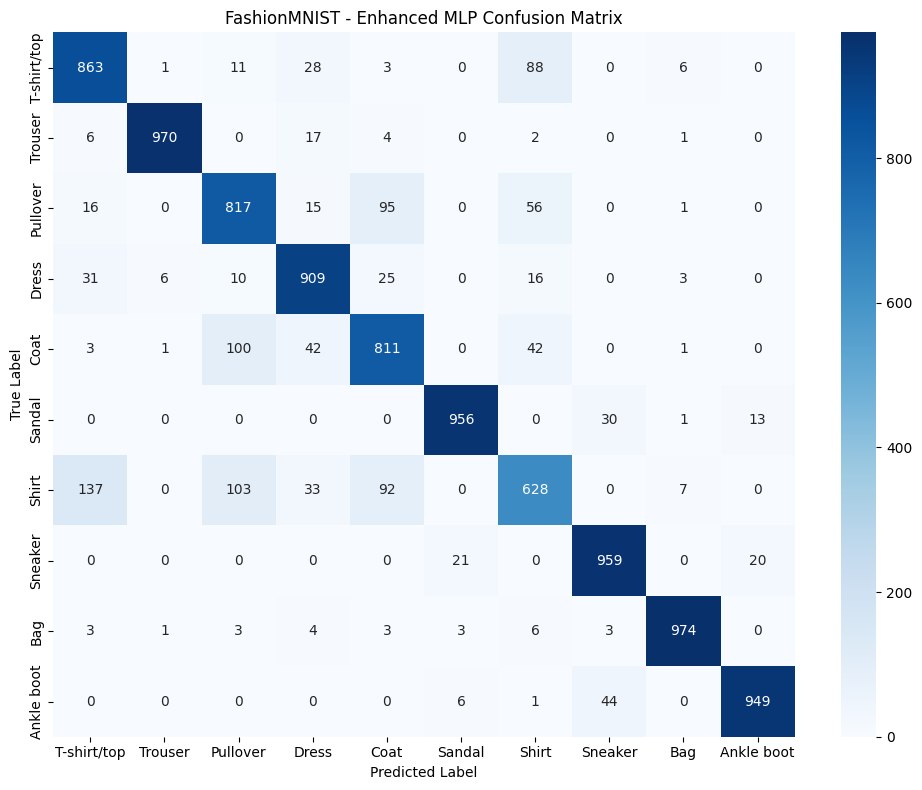

In [ ]:
# -------------------------------------------------------------------------
# FINAL MODEL EVALUATION & CONFUSION MATRIX
# -------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Load the best saved weights into the model
final_model.load_state_dict(torch.load('best_enhanced_model.pt'))
final_model.eval()

all_preds = []
all_targets = []

# Disable gradient calculation for faster evaluation
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = final_model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

# Class names in FashionMNIST
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 2. Print Classification Report (Precision, Recall, F1-Score)
print("--- Classification Report on Test Set ---")
print(classification_report(all_targets, all_preds, target_names=class_names))

# 3. Plot Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('FashionMNIST - Enhanced MLP Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [ ]:
import torch
print("CUDA Var mı?:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Ekran Kartı:", torch.cuda.get_device_name(0))

CUDA Var mı?: True
Ekran Kartı: Tesla T4
